# M10 · Séparabilité linéaire et convexité — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookMaths/blob/main/chapitres/m10_separabilite_convexite/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wbm.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | M10.1 à M10.5, M10.9 | Les exercices papier (vérification) | ✏️ 🔗 | | |
| A | M10.12 | L'enveloppe convexe dans le plan : la chaîne monotone d'Andrew · `convex_hull_2d` | 🔨 | ★★ | 25 |
|  | M10.13 | Séparabilité par programmation linéaire, et marge géométrique · `is_linearly_separable, margin_of_separator` | 🔨 | ★★ | 25 |
| B | M10.14 | Prédire : n points aux labels tirés au hasard en dimension d sont-ils séparables ? | 🔮 | ★ | 10 |
|  | M10.15 | Deux nuages, leurs enveloppes convexes et un hyperplan séparateur avec sa marge | 🎨 | ★ | 15 |
| C | M10.16 | Chasse à l'erreur : un produit vectoriel de signe inversé, une marge non normalisée | 🐛 | ★ | 15 |
|  | M10.17 | Des tests de propriétés pour l'enveloppe convexe | 🛠️ | ★ | 15 |
|  | M10.18 | Défi : la plus grande marge possible entre deux nuages donnés, à 1 % près | 🏆 | ★★★ | 20 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (a few seconds per cell); False = bigger experiments
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookMaths.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookMaths")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WBM_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wbm").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wbm").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier de workbookMaths.")

os.environ["WBM_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wbm  # noqa: E402

cfg = wbm.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mymath = wbm.load_mymath("ref")  # reference implementation

🧪 workbookMaths : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | scipy 1.16.3 | sympy 1.14.0 | matplotlib 3.10.0 | pandas 2.2.3 | scikit-learn 1.6.1
   Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Vérifier tes calculs papier (partie 0) : segments et convexes, enveloppe convexe et produit vectoriel, séparateur et marge, astuce du biais, récurrence sur une norme, activations.
- Écrire les trois fonctions de `mymath/convex.py` et les tester.
- Prédire la séparabilité de labels au hasard, dessiner une marge, chasser deux erreurs, écrire des tests de propriétés, trouver la plus grande marge.

**Rappel express.** Convexe : $(1 - t)\mathbf{a} + t\mathbf{b} \in C$ ; $\mathbf{u} \times \mathbf{v} = u_1v_2 - u_2v_1$, positif à gauche ; séparable $\iff$ $y_i(\mathbf{w} \cdot \mathbf{x}_i + b) \ge 1$ a une solution $\iff$ enveloppes disjointes ; $\tilde{\mathbf{x}} = (1, \mathbf{x})$, $\tilde{\mathbf{w}} = (b, \mathbf{w})$ ; marge $\min_i \frac{y_i(\mathbf{w} \cdot \mathbf{x}_i + b)}{\lVert \mathbf{w} \rVert}$, la plus grande $= \frac{1}{2}\operatorname{dist}(\operatorname{conv} A, \operatorname{conv} B)$ ; $\lVert \mathbf{v}_{k+1} \rVert^2 \le \lVert \mathbf{v}_k \rVert^2 + c \Rightarrow \lVert \mathbf{v}_k \rVert^2 \le \lVert \mathbf{v}_0 \rVert^2 + kc$.

## Partie 0 · Vérifier tes exercices papier (✏️ M10.1 à M10.5, 🔗 M10.9)

Fais d'abord les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse ici : **la valeur** que tu as trouvée, sous la forme indiquée en commentaire, jamais le calcul qui y mène :
- un entier, ou un nombre avec un point décimal, `-1.25`, arrondi comme le demande la question ;
- une liste `[2, -1]` pour un point ou un vecteur, une liste de points `[[1, 0], [-2, 3]]` ;
- `True` / `False`, des lettres entre guillemets, `"BD"`, ou un intervalle entre guillemets, `"]0 ; 4]"` (crochet tourné vers l'extérieur : borne exclue).

Les réponses pas encore remplies affichent ⏳.

In [2]:
# Part 0: the answers are computed exactly from the statements
import math


def sigmoid(z):
    """The logistic function 1 / (1 + exp(-z))."""
    return 1 / (1 + math.exp(-z))

**Ex M10.1 — Convexe ou non : segments, demi-plans, intersections**

In [3]:
wbm.record("M10.1a", [-1, 1], mistakes={"t mesure l'avancée depuis a : le point vaut a + t(b − a)": [3, -1]})
wbm.record("M10.1b", 0.75, decimals=2, mistakes={"t = 0 donne a et t = 1 donne b : t mesure l'avancée depuis a": 0.25})
wbm.record("M10.1c", "ACEF", mistakes={"F est la région au-dessus de la courbe de 1/x, convexe sur ]0, +∞[ : prends deux de ses points": "ACE", "D est la région sous une parabole : le milieu de (−1, 1) et (1, 1) en sort": "ACDEF", "B a un trou : un segment qui traverse le disque unité en sort": "ABCEF", "G est une croix : le segment de (3, 0) à (0, 3) passe par (1,5 ; 1,5), hors des deux bandes": "ACEFG"})
wbm.record("M10.1d", [3, 2], mistakes={"le sommet est l'intersection des droites 2x + y = 8 et x + 2y = 7": [2, 3]})
wbm.record("M10.1e", 4, mistakes={"compte aussi les sommets sur les axes, (0, 0) compris": {2, 3}})
wbm.record("M10.1f", "PS", mistakes={"S est sur le bord x + 2y = 7 : K contient son bord (inégalités larges)": "P", "vérifie les quatre inégalités, x + 2y ≤ 7 comprise": {"PQ", "PQS"}, "vérifie les quatre inégalités, 2x + y ≤ 8 comprise": {"PR", "PRS"}})
wbm.record("M10.1g", [1.4, 1.0], decimals=1, mistakes={"les poids vont avec les points dans l'ordre de l'énoncé : 0,5 pour (2, 0)": [1.0, 0.8]})

WBM_ANSWER {"decimals": 0, "element_hashes": ["4249553b889c274b0b459ae95b7bc4f28cded5d422394011a000d371212d7a6a", "c472fa42845b9221370d44f626d970c8dc471a413441e4f11941969b65cccd92"], "hash": "2e537fe6f97a31ce86880d49718f606688146df68640b4df6d95499d8c87b4c2", "id": "M10.1a", "integer": true, "kind": "array", "mistakes": {"9cefa77b1f78d4b4bbb115c078174a987f3f0f05144e94f88611fd180a506048": "t mesure l'avancée depuis a : le point vaut a + t(b − a)"}, "shape": [2]}
📝 Ex M10.1a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"coarse_any": {"0": ["9177c8285db85919ffdaf2de26bcaad5d36fdc245816a0e852c3b58d465edae0"]}, "decimals": 2, "hash": "5cd473f74dbdb6e3791b282ebd90e0a6678b18fb9c2599756fe64230e46a7547", "hash_coarse": "fb8606a44bee8fa797421d82ad833bbcf15591c7cd9983c70313145617665b47", "id": "M10.1b", "kind": "float", "magnitude": -1, "mistakes": {"fc50a73563eb360263bc723677c086c10bd1479278c39ef916d6b664b8da413b": "t = 0 donne a et t = 1 donne b : t mesure l'avancée depuis a"}, "sign":

**Ex M10.2 — L'enveloppe convexe de huit points, à la main**

In [4]:
wbm.record("M10.2a", 5, mistakes={"un point au milieu d'un côté n'est pas un sommet": 6, "les points intérieurs ne sont pas des sommets : seuls ceux que l'élastique touche en tournant": {7, 8}})
wbm.record("M10.2b", [[-3, 1], [0, -2], [5, 0], [4, 3], [3, 5]], mistakes={"le sens direct est le sens inverse des aiguilles d'une montre": [[-3, 1], [3, 5], [4, 3], [5, 0], [0, -2]], "(−2, 0) est au milieu d'un côté : ce n'est pas un sommet": [[-3, 1], [-2, 0], [0, -2], [5, 0], [4, 3], [3, 5]], "commence par le plus petit point : le plus petit x, puis le plus petit y": [[0, -2], [5, 0], [4, 3], [3, 5], [-3, 1]], "(4, 3) dépasse de peu la droite qui joint (5, 0) à (3, 5) : calcule le produit vectoriel, c'est un sommet": [[-3, 1], [0, -2], [5, 0], [3, 5]]})
wbm.record("M10.2c", 7, mistakes={"ce point est à l'intérieur : un point sur un côté a un produit vectoriel nul avec les deux extrémités du côté": {2, 5}})
wbm.record("M10.2d", 1, mistakes={"u × v = u₁v₂ − u₂v₁ : l'ordre des deux vecteurs compte": -1})
wbm.record("M10.2e", 30, mistakes={"l'aire d'un triangle est la MOITIÉ de la valeur absolue du produit vectoriel": 60})
wbm.record("M10.2f", False, mistakes={"teste Q contre chaque côté, dans le sens direct, celui qui va de (4, 3) à (3, 5) compris": True})
wbm.record("M10.2g", 5, mistakes={"un nouveau point peut faire disparaître un sommet : teste (4, 3) avec ses nouveaux voisins": 6})

WBM_ANSWER {"hash": "d7eed3153d466c62718daf14a204fc9d76923269ebcb0a237dcf062f89c3f519", "id": "M10.2a", "kind": "int", "magnitude": 0, "mistakes": {"843cea63e4d5107ccba2d1ed39c11607ec1e60cd65c7fa5b204ff9fdde078e6c": "les points intérieurs ne sont pas des sommets : seuls ceux que l'élastique touche en tournant", "c332a3ed3aa41ee77a369648b499c50a69ec8d458d0781b9debee6d724e107d7": "un point au milieu d'un côté n'est pas un sommet", "c70a2aebcea77ce50c6de5710f2438e50285506b4f43dbcac7e671c1afc9dad1": "les points intérieurs ne sont pas des sommets : seuls ceux que l'élastique touche en tournant"}, "sign": 1}
📝 Ex M10.2a : réponse enregistrée (int).
WBM_ANSWER {"decimals": 0, "element_hashes": ["c7f15bcba18cdc65387322fdd12ae96ccc6c558a38b400378d1faf566d1440bf", "31936ec122551806ff061f4423768ba72bb16273c0f34e49ed3298cc9118691e", "9de1c915122231289ecb52fd22ed9e74c598978d4ad8340351776810be357d45", "8342f1838a753993c684a55c8e901a54fc31dc722b31fc41a9498ee045dd2feb", "efbdcc417cff133f2cb559c2062ab5

**Ex M10.3 — Une droite qui sépare deux petits nuages, et sa marge**

In [5]:
wbm.record("M10.3a", [16, 15, 8, -2, -5, -2], mistakes={"le score est w · x + b : n'oublie pas b": [20, 19, 12, 2, -1, 2]})
wbm.record("M10.3b", 2 / math.sqrt(5), decimals=4, mistakes={"une marge géométrique est une distance : divise par ‖w‖": 2.0, "‖w‖ = √(2² + 1²), pas 2² + 1²": 0.4, "la marge est le minimum sur les DEUX classes, la classe −1 comprise": 8 / math.sqrt(5), "le score est w · x + b : avec b, tous les points sont du bon côté": -2 / math.sqrt(5)})
wbm.record("M10.3c", [0.8, 2.4], decimals=4, mistakes={"le projeté est P₄ − (w · P₄ + b) / ‖w‖² × w, avec un score de −2 : attention au signe": [-0.8, 1.6], "divise le score par ‖w‖² = 5, pas par ‖w‖": [0.8 * 5 ** 0.5, 2 + 0.4 * 5 ** 0.5]})
wbm.record("M10.3d", "]-12 ; -2[", kind="interval", mistakes={"la séparation est stricte : aux bornes, un point est sur la droite": "[-12 ; -2]", "w · x + b > 0 sur la classe +1 donne b > −12, et < 0 sur la classe −1 donne b < −2": "]2 ; 12["})
wbm.record("M10.3e", -7, mistakes={"le meilleur b met la droite à égale distance des deux nuages : le milieu de l'intervalle": {-12, -2}})
wbm.record("M10.3f", math.sqrt(5), decimals=4, mistakes={"divise par ‖w‖ = √5": 5.0, "‖w‖ = √5, pas 5": 1.0})
wbm.record("M10.3g", 2.5, decimals=2, mistakes={"la plus grande marge est la MOITIÉ de la distance entre les enveloppes": 5.0, "c'est la meilleure marge pour w = (2, 1) ; en changeant aussi la direction, on fait mieux": math.sqrt(5)})

WBM_ANSWER {"decimals": 0, "element_hashes": ["e27b1276ac98420c178e85c502f76bb1d62aa3f050cff975b328735c13ad71ab", "a0004a6bcf0156fb22efd064b48bc6e8e1d83ebe253ead8e7dba8290cdc74e31", "1ec5f428d950a92cd94571feae1c9888ebd40b94c31d4843f9eda072f3117b66", "843fb79d0ff36692c8a530859afcf3837f963ff6d91fd1a4d815b9a9c238a04b", "ee74e65e60f2cd7a80c890e939cd864c55effe2c897a38306c3a003388b3cb1e", "c51c52713c5e2cfa6c61586218edf0d8f81c1eb1b728cbedcf4ade1be3d2c0e9"], "hash": "61a0cd7eabd77c2f28511f38cf1cafd600b12e0274218271993b5709bf3553be", "id": "M10.3a", "integer": true, "kind": "array", "mistakes": {"f1d674ca66d8d8f050b15efbfabcc54f5d469e9f9d17ca990e54d06eda59d8e8": "le score est w · x + b : n'oublie pas b"}, "shape": [6]}
📝 Ex M10.3a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"coarse_any": {"0": ["842cbe9272f9c5106aac365a0863a1c178775f82562f76670d1640830b8ee2b7"], "1": ["f2bde0e510c2f7133ac7e1bda98d622c88ef1ad4e05a80bfa4da66032032153b"]}, "coarser": {"2": ["86601b4d0d4680ce1cb47f656ad9

WBM_ANSWER {"hash": "4ce1225d942ef8cef023fa2f7962617162d1de8fb714a4f8c1396b41cdca8ef0", "id": "M10.3d", "kind": "interval", "mistakes": {"059cf43ced2f8a0c5f4271279b7fc65ed5aab1947ceca39d7f5699d7c31db165": "w · x + b > 0 sur la classe +1 donne b > −12, et < 0 sur la classe −1 donne b < −2", "b3f4d9af43697aeddab35bd317fd6e27dbd392e3ce83518a6e6e9ef867cdbd04": "la séparation est stricte : aux bornes, un point est sur la droite"}}
📝 Ex M10.3d : réponse enregistrée (interval).
WBM_ANSWER {"hash": "8c929dac37d40be69b61a6eaa92ea49005e63c8fefea7fc2bb057c4a0b71adad", "id": "M10.3e", "kind": "int", "magnitude": 0, "mistakes": {"05bb1cf682969c0e5634dd2d6fe1e9b50b0764adb96d4e9dcc5abb2150b9a97d": "le meilleur b met la droite à égale distance des deux nuages : le milieu de l'intervalle", "d7af9b3dd62edf47173d7dfbfec412df755697e765b721b944391959e7a8dc3c": "le meilleur b met la droite à égale distance des deux nuages : le milieu de l'intervalle"}, "sign": -1}
📝 Ex M10.3e : réponse enregistrée (int).
WB

**Ex M10.4 — L'astuce du biais : une droite du plan devient un plan de ℝ³ passant par l'origine**

In [6]:
wbm.record("M10.4a", [1, 0.75, -0.5], decimals=2, mistakes={"c'est un vecteur de Δ ; la question demande celui dont la première coordonnée vaut 1 : divise tout par 4": [4, 3, -2], "multiplie les TROIS coordonnées par le même nombre, 1/4": [1, 3, -2], "le biais se place en tête : (b, w₁, w₂)": [0.75, -0.5, 1]})
wbm.record("M10.4b", [1, 3, -2], mistakes={"la parallèle passe par p : 3 × 1 − 2 × 2 + b′ = 0 donne b′ = 1": [-1, 3, -2], "c'est le vecteur de Δ ; la parallèle doit passer par p": [4, 3, -2], "le biais se place en tête : (b′, w₁, w₂)": [3, -2, 1]})
wbm.record("M10.4c", 3 / math.sqrt(13), decimals=4, mistakes={"divise l'écart des biais par ‖w‖ = √13": 3.0, "‖w‖ = √13, pas 13": 3 / 13, "la distance se mesure dans le plan, avec ‖w‖ = ‖(3, −2)‖, pas avec la norme d'un vecteur relevé": 3 / math.sqrt(14), "les biais valent 4 et 1 : leur écart est 3": 5 / math.sqrt(13)})
wbm.record("M10.4d", 4 / math.sqrt(13), decimals=4, mistakes={"la distance est |w · q + b| / ‖w‖, avec ‖w‖ = ‖(3, −2)‖ dans le plan": 4 / math.sqrt(29), "divise par ‖w‖": 4.0, "‖w‖ = √13, pas 13": 4 / 13})
wbm.record("M10.4e", [3, 2], mistakes={"au niveau x₀ = 1, l'équation devient −6 + 2x₁ + 3x₂ = 0 : x₁ = 3 quand x₂ = 0": [2, 3]})
wbm.record("M10.4f", 2, mistakes={"la coordonnée constante est en tête : ṽ′ = (b, w₁, w₂), avec b = 0, et l'équation devient x₁ − 3x₂ = 0": 3, "x₁ − 3x₂ = 0 : résous en x₂, avec x₁ = 6": 18, "x₁ − 3x₂ = 0 donne x₂ = x₁ / 3, positif": -2})
wbm.record("M10.4g", [-2, 1, 2], mistakes={"le plan doit contenir (1, 2, 0) et (1, 0, 1) : écris les deux produits scalaires nuls": [-2, 2, 1]})

WBM_ANSWER {"decimals": 2, "element_coarse": [["5b943cf18c631ad94db0ce6ce1114c6ba1720e5ea45e72cf152d50b00f298367"], ["76992a6c178546bca172f8089d6a22f275479c4c32b84409f67a02c1f2abc71b"], ["3cc19937381804899b8520c8391820780400056572a28484eb3a56cc875d962a"]], "element_coarse_any": [["e3cf2d4fd02bcdd6c9602c799252409388d6f3f222a093e544cfac236a9e37d9"], ["6ae752167e7c65d3f067cf10fdada732a15aa80a48de638676606a72627185f6"], []], "element_hashes": ["31af5c19002b0da1da77365209ffa73f642a21fd52db936a48683421a5604308", "32ca528030e997b4cfbbff5e32d99320e9637eb0b13c2abefbe00601b40267bb", "234fb58d5cd55f6e1465c77aaf289608cd54c8b4ead354319ceae4e6469d0d74"], "hash": "f085739889084f2f3fb6d9f9b751b0512fcc757b40456febc7d9e3e53f78804c", "id": "M10.4a", "kind": "array", "mistakes": {"08aac54cd4a2dcbf918b8bf40971cde2219727962670c8943eb404b9aabd51c8": "c'est un vecteur de Δ ; la question demande celui dont la première coordonnée vaut 1 : divise tout par 4", "9f1a1d76ef4e4669935110abb432c7f8549d9d7d8c97fdf30400

**Ex M10.5 — Borner une norme pas à pas : ‖v_{k+1}‖² ≤ ‖v_k‖² + c**

In [7]:
wbm.record("M10.5a", 5.0, decimals=2, mistakes={"la question demande le CARRÉ de la norme": math.sqrt(5)})
wbm.record("M10.5b", -1, mistakes={"v₁ = v₀ + d₀ : calcule d'abord v₁, puis son produit scalaire avec d₁": 3})
wbm.record("M10.5c", 13, mistakes={"c'est la borne ; la question demande la valeur exacte, avec le terme 2 v₁ · d₁": 15})
wbm.record("M10.5d", 15, mistakes={"c'est la valeur exacte ; la borne ignore le terme 2 v_k · d_k, ≤ 0": 13, "le lemme ajoute c à chaque pas, à partir de ‖v₀‖² = 5 : deux pas": {10, 20}})
wbm.record("M10.5e", math.sqrt(505), decimals=2, mistakes={"la question demande la norme : prends la racine carrée de la borne du carré": 505.0, "‖v₁₀₀‖² ≤ ‖v₀‖² + 100 c : n'oublie pas ‖v₀‖² = 5": 10 * math.sqrt(5)})
wbm.record("M10.5f", 10.0, decimals=2, mistakes={"c'est la borne de l'inégalité triangulaire, 3 + 1 + 2 + ⋯ + 6 ; le lemme s'applique ici au CARRÉ de la norme": 24.0, "c'est la borne de ‖v₆‖² : prends la racine carrée": 100.0, "chaque pas a sa propre longueur maximale : ajoute 1², 2², …, 6², pas six fois 6²": 15.0, "n'oublie pas le point de départ, ‖v₀‖² = 9": math.sqrt(91), "le lemme ajoute les CARRÉS des longueurs des pas : 1² + 2² + ⋯ + 6²": math.sqrt(30)})
wbm.record("M10.5g", math.sqrt(41), decimals=2, mistakes={"les 5 premiers pas vont dans la direction de la position : la norme gagne 1 à chacun, la borne en √k ne s'applique pas à eux": math.sqrt(11), "les 5 derniers pas sont perpendiculaires à la position : la norme ne gagne plus que par Pythagore, ‖v_(k+1)‖² = ‖v_k‖² + 1": 11.0, "un pas perpendiculaire fait quand même grandir la norme : ‖v_(k+1)‖² = ‖v_k‖² + ‖d_k‖²": 6.0})

WBM_ANSWER {"coarse_any": {"0": ["f967385719100281a51c37c312f6d767028fdd1dd6f7597aeb7834310801027f"]}, "decimals": 2, "hash": "a6ef276b448aabe67cb2ecd2644dd21871c51054bafe5eea94c7eeb9942cb0f6", "hash_coarse": "243dfcee5d47d9356a9a264d406c9051df33a0394fad11b491a8719ec83b2e64", "id": "M10.5a", "kind": "float", "magnitude": 0, "mistakes": {"2e6a5a435eba5e265b3f39389b998c75bd182ca89f164945d0efd4ab845548de": "la question demande le CARRÉ de la norme"}, "sign": 1}
📝 Ex M10.5a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"hash": "f77d7e7ba80093ce8b0053f6618275174318bb82f1917b31976c77bf74ad2294", "id": "M10.5b", "kind": "int", "magnitude": 0, "mistakes": {"7a00b79df0700748bfdb1749ba9c0bb739908f340ce27310f75959efd42f148a": "v₁ = v₀ + d₀ : calcule d'abord v₁, puis son produit scalaire avec d₁"}, "sign": -1}
📝 Ex M10.5b : réponse enregistrée (int).
WBM_ANSWER {"hash": "884db6b928345475682cb07d8ff2896017b7591bfeff535f1a52f635648da47d", "id": "M10.5c", "kind": "int", "magnitude": 1, "mis

**Ex M10.9 — Pont : seuil, sigmoïde, tanh et ReLU appliqués à un même score linéaire**

In [8]:
wbm.record("M10.9a", [0.75, 2.25, -1.75], decimals=2, mistakes={"le score est w · x + b, avec b = −1 : n'oublie pas b": [1.75, 3.25, -0.75], "w = (4, −3) : le second poids est négatif": [7.5, 4.75, -0.25]})
wbm.record("M10.9b", [1, 1, 0], mistakes={"le seuil vaut 0 ou 1 : H(z) = 0 pour z ≤ 0, jamais −1": [1, 1, -1], "H donne 0 ou 1, pas le score : 1 si z > 0": [0.75, 2.25, 0]})
wbm.record("M10.9c", [sigmoid(0.75), sigmoid(2.25), sigmoid(-1.75)], decimals=4, mistakes={"σ(z) = 1/(1 + e^(−z)) : le signe dans l'exponentielle": [sigmoid(-0.75), sigmoid(-2.25), sigmoid(1.75)]})
wbm.record("M10.9d", [math.tanh(0.75), math.tanh(2.25), math.tanh(-1.75)], decimals=4, mistakes={"tanh(z) = 2σ(2z) − 1, pas 2σ(z) − 1": [2 * sigmoid(0.75) - 1, 2 * sigmoid(2.25) - 1, 2 * sigmoid(-1.75) - 1]})
wbm.record("M10.9e", [0.75, 2.25, 0], decimals=2, mistakes={"ReLU(z) = max(0, z) garde z quand il est positif": [1, 1, 0], "ReLU(z) = max(0, z) : un score négatif donne 0": [0.75, 2.25, -1.75]})
wbm.record("M10.9f", sigmoid(2.5), decimals=4, mistakes={"une distance n'est pas un score : à la distance d, le score vaut d × ‖w‖ = 0,5 × 5": sigmoid(0.5), "le score vaut la distance MULTIPLIÉE par ‖w‖ = 5": sigmoid(0.1), "‖w‖ = √(4² + 3²) = 5, pas 25": sigmoid(12.5)})
wbm.record("M10.9g", math.log(17 / 3) / 5, decimals=4, mistakes={"un score n'est une distance qu'une fois divisé par ‖w‖ = 5": math.log(17 / 3), "‖w‖ = 5, pas 25": math.log(17 / 3) / 25, "σ(z) = 0,85 donne 1 + e^(−z) = 1/0,85 : isole e^(−z) avant de prendre le logarithme": math.log(1 / 0.85) / 5})

WBM_ANSWER {"decimals": 2, "element_coarse": [["8d6a40cb5f19de2696ac4f1a9a9f5a74447d83acf5f1d7f0061d9ff30f702853"], ["727e7cbaeab0e6cb427b10c711adf8cff59ec009828712b5dc8922519fc86c43", "5157b5b764ba8b0fa96d13b8ab1e550d538d15721cd3d090b6ba790591400ea8"], ["fbf963ae72fbc2fb333568efbf44b357c19862ed396976eda813b663c134cb8c"]], "element_coarse_any": [["c0162b2ae87242b568f82572dfecd7f0d97712a5f9f11e1da35db2625e6071ab"], ["f4d7b3c2323cbbcf84546a7fdda53f365724577de1da00d3be0a6ef0447d35a8"], ["3507fa3550328612129ae8820cdffb0bb6b3453944d8629361741a0dd0914e54"]], "element_hashes": ["3ef4ed16535d00841b201543ca56da211156d99e449ade25559dd3b4d058d6d4", "53a80f30fb9388357b4d8802537e852467d5c859952fe07421e43d4c5a9c1176", "5c88446ad007f8e73015abdef0507a1284916cd0152dd2b50cd07042a0c0e2bc"], "hash": "19ca41a77372984c43aa9fe19bb142d6186feef3fd6cde82f3ff465af37e316a", "id": "M10.9a", "kind": "array", "mistakes": {"50bb0e0bdaac8d6e0ac35075bb4a57ffe2d9b6de35dd527ace312eb6c5597f8b": "le score est w · x + b, av

## Partie A · Ta librairie : enveloppe convexe, séparabilité, marge

Fiche §2 et §3. Les trois fonctions de `mymath/convex.py`.

In [9]:
# Tools of the notebook (parts A to C)
import ast
import inspect
import textwrap

import matplotlib.pyplot as plt
import numpy as np

from wbm.nbtools import checked, drawn, run_pytest_group


def raised(function, *args, **kwargs):
    """The name of the exception that function(*args, **kwargs) raises, or "aucune" if it returns.

    NotImplementedError (a TODO not done yet) goes through, for wbm.attempt to show ⏳; so do the errors of a code
    that cannot run (a missing import, a misspelt name such as ValueErorr), for the check to name them."""
    try:
        function(*args, **kwargs)
    except (NotImplementedError, NameError, AttributeError, ImportError):
        raise
    except Exception as exc:  # noqa: BLE001 - any other error is the answer
        return type(exc).__name__
    return "aucune"

### Ex M10.12 — L'enveloppe convexe dans le plan : la chaîne monotone d'Andrew · `convex_hull_2d` 🔨 ★★ ⏱️ 25 min
**Objectif :** programmer la chaîne monotone d'Andrew, avec ses cas particuliers : points répétés, alignés, au milieu d'un côté.  
**Prérequis :** fiche §2 · **mymath :** `convex.py` · **Parcours :** C, E

> **Mode d'emploi `mymath`** (comme en M03). Ouvre ta copie `mon_travail/mymath/convex.py`, lis la docstring du module puis celle de la fonction, remplace la ligne `raise NotImplementedError(...)` par ton code, **enregistre** le fichier, puis exécute les cellules ci-dessous : la première recharge ta librairie. NumPy est permis, et `scipy.optimize.linprog` pour `is_linearly_separable` ; `scipy.spatial` est interdit (les tests comparent ton enveloppe à `scipy.spatial.ConvexHull`, et un test vérifie que tu ne t'en sers pas). Ne modifie jamais les tableaux reçus.

Écris `convex_hull_2d(points)` (fiche §2), en suivant la docstring : les points distincts triés par $x$ puis par $y$ (`np.unique(P, axis=0)` le fait), la chaîne du bas de gauche à droite, la chaîne du haut de droite à gauche, en retirant le dernier sommet tant que le produit vectoriel est $\le 0$, puis les deux chaînes bout à bout sans répéter leurs extrémités. Le résultat : un tableau NumPy de floats de forme $(h, 2)$, les sommets dans le sens direct à partir du plus petit point. Une `ValueError` si le nuage est vide ou n'a pas deux colonnes.

Avec $P$ = `[[2, -1], [6, 0], [7, 4], [3, 6], [-1, 3], [4, 2], [5, 5], [0, 0], [2, 3], [4, -0.5]]`, la vérification calcule :
- a) `convex_hull_2d(P)` (une liste de points) ;
- b) le nombre de sommets de l'enveloppe de 200 points tirés par `np.random.default_rng(12).normal(size=(200, 2))` ;
- c) `convex_hull_2d([[-2, 3], [4, -3], [0, 1], [2, -1]])` (quatre points alignés) ;
- d) le nom de l'erreur levée par `convex_hull_2d([])` ;
- e) le nom de l'erreur levée par `convex_hull_2d([[1, 2, 3], [4, 5, 6]])` ;
- f) le nom du type de la valeur rendue, en texte.

Dans ta copie : dessine $P$ et son enveloppe. Quel point de $P$ est au milieu d'un côté ? Quel test de ta boucle l'écarte ? Que rendrait ta fonction si le test était $< 0$ au lieu de $\le 0$ ?

In [10]:
mymath = wbm.load_mymath("ref")
convex_hull_2d = mymath.convex.convex_hull_2d
P_12 = [[2, -1], [6, 0], [7, 4], [3, 6], [-1, 3], [4, 2], [5, 5], [0, 0], [2, 3], [4, -0.5]]
print("a)", convex_hull_2d(P_12).tolist())
print("b)", len(convex_hull_2d(np.random.default_rng(12).normal(size=(200, 2)))))
print("c)", convex_hull_2d([[-2, 3], [4, -3], [0, 1], [2, -1]]).tolist())
print("d)", raised(convex_hull_2d, []), " e)", raised(convex_hull_2d, [[1, 2, 3], [4, 5, 6]]),
      " f)", type(convex_hull_2d(P_12)).__name__)

a) [[-1.0, 3.0], [0.0, 0.0], [2.0, -1.0], [6.0, 0.0], [7.0, 4.0], [3.0, 6.0]]
b) 11
c) [[-2.0, 3.0], [4.0, -3.0]]
d) ValueError  e) ValueError  f) ndarray


In [11]:
wbm.record("M10.12a", [[-1.0, 3.0], [0.0, 0.0], [2.0, -1.0], [6.0, 0.0], [7.0, 4.0], [3.0, 6.0]], decimals=6,
           mistakes={"(4 ; −0,5) est au milieu d'un côté : retire le dernier sommet quand le produit vectoriel est "
                      "≤ 0, pas seulement < 0": [[-1.0, 3.0], [0.0, 0.0], [2.0, -1.0], [4.0, -0.5], [6.0, 0.0],
                                                 [7.0, 4.0], [3.0, 6.0]],
                      "le sens direct est le sens inverse des aiguilles d'une montre : vérifie le signe du produit "
                      "vectoriel": [[-1.0, 3.0], [3.0, 6.0], [7.0, 4.0], [6.0, 0.0], [2.0, -1.0], [0.0, 0.0]],
                      "le premier sommet est le plus petit point dans l'ordre du tri : le plus petit x d'abord":
                          [[2.0, -1.0], [6.0, 0.0], [7.0, 4.0], [3.0, 6.0], [-1.0, 3.0], [0.0, 0.0]]})
wbm.record("M10.12b", 11)
wbm.record("M10.12c", [[-2.0, 3.0], [4.0, -3.0]], decimals=6,
           mistakes={"les points au milieu d'un segment ne sont pas des sommets : seules les deux extrémités restent":
                         [[-2.0, 3.0], [0.0, 1.0], [2.0, -1.0], [4.0, -3.0]],
                     "les deux chaînes se rejoignent à leurs extrémités : ne répète pas le premier sommet":
                         [[-2.0, 3.0], [4.0, -3.0], [-2.0, 3.0]]})
wbm.record("M10.12d", "ValueError",
           mistakes={"un nuage vide n'a pas d'enveloppe : la docstring demande une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError"}})
wbm.record("M10.12e", "ValueError",
           mistakes={"des points à trois coordonnées ne sont pas des points du plan : la docstring demande une "
                      "ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError"}})
wbm.record("M10.12f", "ndarray", mistakes={"la docstring demande un tableau NumPy de floats : np.array(...)": {"list", "tuple"}})

WBM_ANSWER {"decimals": 6, "element_coarse": [["bb09f680d5ac406dc24548172e4fc20fae7375f19ff52ce650fbbe71d59bee08"], ["594cc90b3c1470a004223db04b3c4a18e91ee6932d7c2b371463dec84d157fbc"], ["13ecf7594dd7cd3db54a0aae1e3fb9a7df054479612d9d8e10f553bbae7f5db9"], ["09d56af18a5bf937455f7a02149824efa31795a0f1b85c55b76b574ac4b7145b"], ["614a963f3638ac4f03c5edbeda6d89afff80ad6217038a547008ced2ed00feba"], ["7e6438652c18f8ee8ca7c68f6a1dc9988a152898a9ef5203e68bd1b66c73bcc9"], ["0369b67a3819c7da78c3eba31777e0fedc19ae2b2b23ec16decb32a6f1c49833"], ["616ef7a9b3b41c1b2e4b88c9cbd0edbb503f45f29b490be096fd4a3d1fe4ff0c"], ["77cde206aa6857969e23cc227997d7a35d0a87127c6cc74160673d4f9b324cc6"], ["e4acf18d42449316808eef37bb46f96d960b6b1171f0344a55b3601f2293ce6c"], ["5869ff5fc0c6071f30c32bf12e8fd4d3c5318c51fe8068b61ef423248b90dd15"], ["a908258ccb3ced43f513385bc7485c01a91b3575eacc97b88988074ca9dd4af2"]], "element_coarse_any": [["fe45e4d7ca40aed88b57f1cb2c59b81f622e3bde002d0eb87fd666f95e72a428", "1ac6fbee37b390958445

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [12]:
run_pytest_group("tests/test_m10_convex.py", "convex_hull_2d or test_convex_uses_", impl="ref")

pytest: 24 réussi(s), 42 non sélectionné(s) en 0,80 s


💡 a) Le point $(4 ;\ -0{,}5)$ est au milieu du côté qui joint $(2, -1)$ à $(6, 0)$ : le produit vectoriel $(2 ;\ 0{,}5) \times (2 ;\ 0{,}5) = 0$ le fait retirer ; les points $(4, 2)$, $(5, 5)$ et $(2, 3)$ sont à l'intérieur. b) Pour un nuage gaussien, l'enveloppe n'a que quelques sommets (de l'ordre de $\sqrt{\ln n}$ en moyenne ; ici 11 sur 200 points) : presque tous les points sont à l'intérieur. c) Tous les produits vectoriels sont nuls : chaque chaîne garde ses deux extrémités, et le résultat aussi.

### Ex M10.13 — Séparabilité par programmation linéaire, et marge géométrique · `is_linearly_separable, margin_of_separator` 🔨 ★★ ⏱️ 25 min
**Objectif :** décider la séparabilité par un programme linéaire de faisabilité, et calculer la marge géométrique d'un séparateur.  
**Prérequis :** fiche §3 ; M07 (distance à un hyperplan) · **mymath :** `convex.py` · **Parcours :** C, E

Écris, en suivant les docstrings (fiche §3) :
- `is_linearly_separable(X, y)` : `True` si et seulement si le système $y_i(\mathbf{w} \cdot \mathbf{x}_i + b) \ge 1$ a une solution $(\mathbf{w}, b)$, décidé par `scipy.optimize.linprog` (objectif nul, contraintes $-y_i(\mathbf{w} \cdot \mathbf{x}_i + b) \le -1$ écrites ligne par ligne, inconnues libres : `bounds=(None, None)`) ; un `bool` de Python ; une `ValueError` si les longueurs diffèrent ou si un label n'est ni $-1$ ni $+1$ ;
- `margin_of_separator(X, y, w, b)` : $\min_i \frac{y_i(\mathbf{w} \cdot \mathbf{x}_i + b)}{\lVert \mathbf{w} \rVert}$, un `float` de Python ; une `ValueError` si les longueurs ne vont pas, si un label n'est ni $-1$ ni $+1$, ou si $\mathbf{w}$ est nul.

Avec $\mathbf{X}$ = `[[-1, 2], [2, 1], [1, -2], [-2, -1], [5, 4], [6, 1], [4, 6], [7, 5]]` et $\mathbf{y}$ = `[1, 1, 1, 1, -1, -1, -1, -1]`, la vérification calcule :
- a) `is_linearly_separable(X, y)` ;
- b) la même chose après avoir ajouté le point $(0{,}5 ;\ 1{,}5)$ avec le label $-1$ ;
- c) `is_linearly_separable([[0], [2], [3], [5], [6]], [1, 1, -1, 1, -1])` ;
- d) `margin_of_separator(X, y, [-1, -1], 4)` (4 décimales) ;
- e) `margin_of_separator(X, y, [2, 2], -8)` (4 décimales) ;
- f) le nom de l'erreur levée par `margin_of_separator(X, y, [0, 0], 1)` ;
- g) le nom de l'erreur levée par `is_linearly_separable([[0, 0], [1, 1]], [0, 1])` ;
- h) vrai ou faux : `is_linearly_separable` rend un `bool` de Python et `margin_of_separator` un `float` de Python (`type(r) is bool and type(m) is float`).

Dans ta copie : où est l'origine par rapport aux quatre points de la classe $+1$ ? Pourquoi a) serait-il faux sans la colonne de 1 (sans le biais $b$) ? Pourquoi b) est-il faux, sans aucun calcul de droite (fiche §3) ? Écris d) à la main : quel point est le plus proche de la droite $-x_1 - x_2 + 4 = 0$ ? Pourquoi e) est-il négatif, et pourquoi n'est-il pas l'opposé de d) ? Que rendrait `is_linearly_separable` avec des contraintes $\ge 0$ au lieu de $\ge 1$ ?

In [13]:
mymath = wbm.load_mymath("ref")
is_linearly_separable, margin_of_separator = mymath.convex.is_linearly_separable, mymath.convex.margin_of_separator
X_13, y_13 = [[-1, 2], [2, 1], [1, -2], [-2, -1], [5, 4], [6, 1], [4, 6], [7, 5]], [1, 1, 1, 1, -1, -1, -1, -1]
print("a)", is_linearly_separable(X_13, y_13), " b)", is_linearly_separable(X_13 + [[0.5, 1.5]], y_13 + [-1]),
      " c)", is_linearly_separable([[0], [2], [3], [5], [6]], [1, 1, -1, 1, -1]))
print("d)", round(margin_of_separator(X_13, y_13, [-1, -1], 4), 4),
      " e)", round(margin_of_separator(X_13, y_13, [2, 2], -8), 4))
print("f)", raised(margin_of_separator, X_13, y_13, [0, 0], 1),
      " g)", raised(is_linearly_separable, [[0, 0], [1, 1]], [0, 1]))
print("h)", type(is_linearly_separable(X_13, y_13)) is bool and type(margin_of_separator(X_13, y_13, [-1, -1], 4)) is float)

a) True  b) False  c) False
d) 0.7071  e) -5.6569
f) ValueError  g) ValueError
h) True


In [14]:
wbm.record("M10.13a", True,
           mistakes={"ces deux nuages sont séparables, mais aucune droite qui passe par l'origine ne les sépare : garde le "
                      "biais b parmi les inconnues (une colonne de 1), et des inconnues libres, bounds=(None, None)": False})
wbm.record("M10.13b", False,
           mistakes={"(0,5 ; 1,5) est le milieu de deux points de la classe +1 : exige y_i(w · x_i + b) ≥ 1, pas ≥ 0":
                         True})
wbm.record("M10.13c", False,
           mistakes={"en dimension 1, le point 3, de la classe −1, est entre deux points de la classe +1 : exige "
                      "y_i(w · x_i + b) ≥ 1": True})
wbm.record("M10.13d", 1 / 2 ** 0.5, decimals=4,
           mistakes={"divise par ‖w‖ = √2": 1.0, "‖w‖ = √2, pas 2": 0.5,
                     "la marge est le MINIMUM des y_i(w · x_i + b) / ‖w‖": 8 / 2 ** 0.5,
                     "multiplie chaque score par le label y_i": -12 / 2 ** 0.5})
wbm.record("M10.13e", -8 / 2 ** 0.5, decimals=4,
           mistakes={"la marge est signée : un point du mauvais côté compte en négatif": 8 / 2 ** 0.5,
                     "la marge est le minimum, ici atteint par le point le plus loin du mauvais côté": -1 / 2 ** 0.5})
wbm.record("M10.13f", "ValueError",
           mistakes={"w = 0 ne définit aucun hyperplan : la docstring demande une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError"}})
wbm.record("M10.13g", "ValueError",
           mistakes={"les labels doivent valoir −1 ou +1 : la docstring demande une ValueError pour 0": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError"}})
wbm.record("M10.13h", True,
           mistakes={"la docstring demande un bool et un float de Python : un booléen ou un nombre de NumPy s'affiche "
                      "autrement (np.True_, np.float64(...)) ; écris bool(...) et float(...)": False})

WBM_ANSWER {"hash": "28961c163651cc57f0e251d754fbe504ff2a00c59f8913cbe32e2bbec7849718", "id": "M10.13a", "kind": "bool", "mistakes": {"d09b45a11cad7eb719b08fb2d86562e679614e650d00af8617c3896abfd15392": "ces deux nuages sont séparables, mais aucune droite qui passe par l'origine ne les sépare : garde le biais b parmi les inconnues (une colonne de 1), et des inconnues libres, bounds=(None, None)"}}
📝 Ex M10.13a : réponse enregistrée (bool).
WBM_ANSWER {"hash": "3a580ed860b37d34e71529b2a378b5a6a17012e1ca7d760ca4dce24bb1a1776f", "id": "M10.13b", "kind": "bool", "mistakes": {"c3405cba659a45766efbd1a797aefe65b4035014d3574b68e6c2ee1ae3f72e2c": "(0,5 ; 1,5) est le milieu de deux points de la classe +1 : exige y_i(w · x_i + b) ≥ 1, pas ≥ 0"}}
📝 Ex M10.13b : réponse enregistrée (bool).
WBM_ANSWER {"hash": "9a209824230277ff2ba2e514799a217a6bd21164996dceddfe4483054c989c1f", "id": "M10.13c", "kind": "bool", "mistakes": {"91e7d99d48b74fe87790c4aa673d5574fb894824570730981bba71f5e935ed45": "en dimensi

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [15]:
run_pytest_group("tests/test_m10_convex.py", "is_linearly_separable or margin_of_separator or test_convex_uses_", impl="ref")

pytest: 43 réussi(s), 23 non sélectionné(s) en 0,82 s


💡 a) L'origine est à l'intérieur de l'enveloppe de la classe $+1$ (un carré autour d'elle) : une droite qui passe par l'origine laisse toujours un de ses sommets de l'autre côté ou dessus ; sans la colonne de 1, le programme linéaire n'a pas de solution, et la fonction rendrait `False`. b) Le point $(0{,}5 ;\ 1{,}5)$ est le milieu de $(-1, 2)$ et $(2, 1)$, deux points de la classe $+1$ : il est dans les deux enveloppes, aucune droite ne sépare (fiche §3). c) Le point 3, de la classe $-1$, est dans l'intervalle $[0, 5]$, l'enveloppe de la classe $+1$. d) Les scores $-x_1 - x_2 + 4$ valent $3, 1, 5, 7$ sur la classe $+1$ et $-5, -3, -6, -8$ sur l'autre : le plus petit $y_i s_i$ est 1, atteint en $(2, 1)$, et $\frac{1}{\sqrt{2}} \approx 0{,}7071$. e) $(2, 2)$ et $-8$ font $-2$ fois le couple de d) : les côtés sont échangés, et le minimum des $y_i s_i$ devient moins le **maximum** de ceux de d), $-\frac{16}{2\sqrt{2}}$, atteint en $(7, 5)$. Avec $\ge 0$, $\mathbf{w} = \mathbf{0}$ et $b = 0$ satisfont toutes les contraintes : la fonction rendrait toujours `True`.

## Partie B · Une prédiction et une figure

Fiche §2 et §3. La séparabilité de labels tirés au hasard, puis tout le §3 sur une seule figure.

### Ex M10.14 — Prédire : n points aux labels tirés au hasard en dimension d sont-ils séparables ? 🔮 ★ ⏱️ 10 min
**Objectif :** prévoir à quelle vitesse la séparabilité devient rare quand le nombre de points grandit devant la dimension, puis le mesurer.  
**Prérequis :** fiche §3 · **Parcours :** C, E

On tire $n$ points au hasard dans $\mathbb{R}^d$ (des coordonnées gaussiennes : presque sûrement en position générale), et on donne à chacun un label $-1$ ou $+1$ à pile ou face. Les deux classes sont-elles linéairement séparables ? La fiche (§3) dit que $d + 1$ points le sont toujours. Pour chaque cas, choisis le numéro de la bonne réponse : la proportion des tirages séparables est (1) 100 % ; (2) entre 65 % et 95 % ; (3) entre 35 % et 65 % ; (4) moins de 5 % :
- a) $n = 3$ points sur une droite ($d = 1$) ;
- b) $n = 6$ points dans le plan ($d = 2$) ;
- c) $n = 22$ points en dimension $d = 10$ ;
- d) $n = 30$ points dans le plan.

**Avant d'exécuter quoi que ce soit**, écris tes quatre prédictions (le **numéro du choix**), vérifie-les, puis lance l'expérience : 300 tirages par cas, décidés par la référence de `is_linearly_separable`.

In [16]:
reference_14 = wbm.load_mymath("ref", alias="mymath_ref")     # the experiment uses the reference of convex.py


def separable_fraction(n, d, trials=300, seed=14):
    """The fraction of `trials` draws of n Gaussian points of R^d, with labels -1 or +1 drawn at random, that are
    linearly separable."""
    rng = np.random.default_rng(seed)
    count = 0
    for _ in range(trials):
        X = rng.normal(size=(n, d))
        y = rng.choice([-1, 1], size=n)
        count += reference_14.convex.is_linearly_separable(X, y)
    return count / trials

In [17]:
wbm.record("M10.14a", 2, prediction=True, choices=[1, 2, 3, 4])
wbm.record("M10.14b", 3, prediction=True, choices=[1, 2, 3, 4])
wbm.record("M10.14c", 3, prediction=True, choices=[1, 2, 3, 4])
wbm.record("M10.14d", 4, prediction=True, choices=[1, 2, 3, 4])

WBM_ANSWER {"choices": ["1", "2", "3", "4"], "hash": "4f812e7c8f176660c0dcd95204fbdf9a3f79745513bc60457a80efb71b8f0029", "id": "M10.14a", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M10.14a : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3", "4"], "hash": "b0f5edc28a829b65917f61c0f603f317c95516a2f6bc458b861d3982483c7b62", "id": "M10.14b", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M10.14b : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3", "4"], "hash": "6a2e246e402356bf61aba65c473a9fe41e655249ad10979a9b598c5e73f3e2ba", "id": "M10.14c", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M10.14c : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3", "4"], "hash": "931844e575525ac7d9f1ed19f3859db41729f62f5d3b8e352b4f5182a6eac302", "id": "M10.14d", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M10.14d : réponse enregistrée (int).


**L'expérience.** Elle ne s'exécute qu'une fois tes quatre prédictions écrites.

In [18]:
for letter, (n, d) in zip("abcd", [(3, 1), (6, 2), (22, 10), (30, 2)]):
    print(f"{letter}) n = {n:2d} points, dimension d = {d:2d} : séparables dans {separable_fraction(n, d):.0%} des "
          f"tirages")

a) n =  3 points, dimension d =  1 : séparables dans 76% des tirages


b) n =  6 points, dimension d =  2 : séparables dans 54% des tirages


c) n = 22 points, dimension d = 10 : séparables dans 49% des tirages


d) n = 30 points, dimension d =  2 : séparables dans 0% des tirages


**Après l'expérience**, dans ta copie : pour a), écris les huit étiquetages de trois points d'une droite ; lesquels ne sont pas séparables (pense au critère des enveloppes, fiche §3) ? Que remarques-tu en b) et en c), qui ont tous deux $n = 2(d + 1)$ ? Combien de points faut-il, en dimension $d$, pour que des labels au hasard ne soient presque jamais séparables ? Qu'est-ce que cela dit d'un classifieur linéaire qui sépare parfaitement ses données d'entraînement quand $d$ est grand devant $n$ ?

💡 T. M. Cover (1965) a compté les étiquetages séparables : pour $n$ points en position générale de $\mathbb{R}^d$, avec un biais, la proportion est $P(n, d) = 2^{1-n}\sum_{k=0}^{d} \binom{n-1}{k}$. a) $P(3, 1) = \frac{1 + 2}{4} = \frac{3}{4}$ : deux étiquetages sur 8 échouent, les deux où le point du milieu est seul de sa classe (il est dans l'enveloppe de l'autre classe, le segment des deux extrêmes). b) et c) $n = 2(d + 1)$ donne exactement $\frac{1}{2}$, quelle que soit la dimension (la somme prend la moitié des coefficients binomiaux, par symétrie). d) $P(30, 2) = \frac{1 + 29 + 406}{2^{29}} \approx 8 \times 10^{-7}$. Avec l'astuce du biais, tout se passe en dimension $d + 1$ : la « capacité » d'un classifieur linéaire est d'environ $2(d + 1)$ points. Quand $d$ est grand devant $n$, séparer parfaitement l'entraînement ne prouve rien : n'importe quels labels le sont.

### Ex M10.15 — Deux nuages, leurs enveloppes convexes et un hyperplan séparateur avec sa marge 🎨 ★ ⏱️ 15 min
**Objectif :** dessiner d'un coup tout le §3 : deux nuages, leurs enveloppes convexes, une droite séparatrice et la bande de sa marge.  
**Prérequis :** fiche §2 et §3 ; Ex M10.12 et M10.13 · **Parcours :** C

Écris `draw_15(ax, X, y, w, b)`, qui dessine dans l'axe `ax` :
- les points, avec `ax.scatter`, une couleur par classe ;
- l'enveloppe convexe de chaque classe (calculée par `mymath.convex.convex_hull_2d`), comme un **polygone fermé** : `ax.plot` sur ses sommets, en répétant le premier à la fin ;
- la droite $\mathbf{w} \cdot \mathbf{x} + b = 0$ et les deux droites parallèles à la distance $\gamma$ de part et d'autre, où $\gamma$ est la marge de $(\mathbf{w}, b)$ (`mymath.convex.margin_of_separator`) : chacune avec `ax.plot`, sur deux points ou plus (sur la droite $\mathbf{w} \cdot \mathbf{x} + b = c$, résous en $x_2$ si $w_2 \ne 0$).

La cellule de la figure s'en sert sur les données de M10.13 ; une cellule de vérification l'essaie sur d'autres données, dans des axes neufs.

Dans ta copie : quels points touchent les bords de la bande ? Pourquoi la bande ne contient-elle aucun point ? Déplace la droite sans changer sa direction pour élargir la bande : jusqu'où peux-tu aller (M10.3 e) ?

In [19]:
X_15 = np.array([[-1, 2], [2, 1], [1, -2], [-2, -1], [5, 4], [6, 1], [4, 6], [7, 5]], dtype=float)
y_15 = np.array([1, 1, 1, 1, -1, -1, -1, -1])
w_15, b_15 = np.array([-1.0, -1.0]), 4.0                 # a separator of the two clouds (the one of M10.13 d)

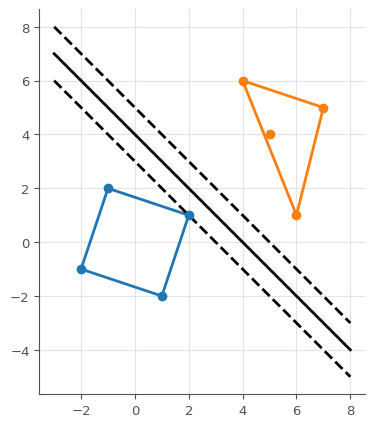

In [20]:
def draw_15(ax, X, y, w, b):
    """In ax: the two clouds (one color per class), their convex hulls as closed polygons, the line w · x + b = 0 and
    the two parallel lines at the distance of the margin, on each side."""
    X, y, w = np.asarray(X, dtype=float), np.asarray(y), np.asarray(w, dtype=float)
    for label, color in ((1, "tab:blue"), (-1, "tab:orange")):
        cloud = X[y == label]
        ax.scatter(cloud[:, 0], cloud[:, 1], color=color, zorder=3)
        hull = mymath.convex.convex_hull_2d(cloud)
        ring = np.vstack([hull, hull[:1]])
        ax.plot(ring[:, 0], ring[:, 1], color=color)
    gamma = mymath.convex.margin_of_separator(X, y, w, b)
    norm = float(np.linalg.norm(w))
    xs = np.array([X[:, 0].min() - 1, X[:, 0].max() + 1])
    for level, style in ((0.0, "-"), (gamma * norm, "--"), (-gamma * norm, "--")):   # w · x + b = level
        ax.plot(xs, (level - b - w[0] * xs) / w[1], color="k", linestyle=style)


fig, ax = plt.subplots(figsize=(6, 5))
draw_15(ax, X_15, y_15, w_15, b_15)
ax.set_aspect("equal")
plt.show()

**Vérifications automatiques** (sur d'autres données, dans des axes neufs).

In [21]:
with checked("M10.15 vérifications"):
    from matplotlib.patches import Polygon as PolygonPatch
    reference_15 = wbm.load_mymath("ref", alias="mymath_ref")
    problems = []
    X_t = np.array([[0.0, 4.0], [1.0, 7.0], [3.0, 6.0], [2.0, 5.0], [-1.0, 6.0],         # other data: hulls of 5 and 4
                    [4.0, 1.0], [6.0, 2.0], [5.0, -1.0], [7.0, 0.0], [5.5, 0.5]])        # vertices, one point inside
    y_t = np.array([1, 1, 1, 1, 1, -1, -1, -1, -1, -1])

    def same_polygon(ring, hull):
        """True if the closed ring visits the vertices of hull in a cyclic order (either way round)."""
        if len(ring) < 2 or not np.allclose(ring[0], ring[-1]) or len(ring) - 1 != len(hull):
            return False
        r = ring[:-1]
        return any(np.allclose(np.roll(seq, -s, axis=0), hull) for seq in (r, r[::-1]) for s in range(len(r)))

    w_t, b_t = np.array([-1.0, 2.0]), -3.0
    gamma_t = reference_15.convex.margin_of_separator(X_t, y_t, w_t, b_t)
    fig_t, ax_t = plt.subplots()
    try:
        created = drawn(draw_15, ax_t, X_t, y_t, w_t, b_t)
    finally:
        plt.close(fig_t)
    if created:
        problems.append("draw_15 ouvre sa propre figure : dessine dans l'axe reçu")
    else:
        rings = [np.asarray(line.get_xydata(), dtype=float) for line in ax_t.get_lines()]
        rings += [np.asarray(patch.get_xy(), dtype=float) for patch in ax_t.patches if isinstance(patch, PolygonPatch)]
        for label, name in ((1, "+1"), (-1, "−1")):
            hull_t = reference_15.convex.convex_hull_2d(X_t[y_t == label])
            if not any(same_polygon(r, hull_t) for r in rings):
                problems.append(f"l'enveloppe de la classe {name} doit être un polygone fermé qui suit, dans l'ordre, les "
                                f"sommets de convex_hull_2d (ax.plot en répétant le premier sommet à la fin)")
        norm_t = float(np.linalg.norm(w_t))
        levels = []
        for line in ax_t.get_lines():
            xy = np.asarray(line.get_xydata(), dtype=float)
            if len(xy) >= 2 and np.ptp(xy[:, 0]) + np.ptp(xy[:, 1]) > 0:
                distances = (xy @ w_t + b_t) / norm_t
                if np.ptp(distances) < 1e-6:
                    levels.append(float(distances[0]))
        for target, what in ((0.0, "la droite séparatrice w · x + b = 0"),
                             (gamma_t, "le bord de la marge du côté +1, à la distance γ"),
                             (-gamma_t, "le bord de la marge du côté −1, à la distance γ")):
            if not any(abs(level - target) < 1e-6 for level in levels):
                problems.append(f"il manque {what} (une droite tracée avec ax.plot)")
        offsets = [np.asarray(c.get_offsets(), dtype=float) for c in ax_t.collections if len(c.get_offsets())]
        shown = {tuple(np.round(p, 6)) for o in offsets for p in o}
        if not {tuple(np.round(p, 6)) for p in X_t} <= shown:
            problems.append("dessine tous les points (ax.scatter), une couleur par classe")
    if problems:
        print("❌ Ex M10.15 : à revoir : " + " ; ".join(problems) + ".")
    else:
        print("✅ Ex M10.15 : les points, les deux enveloppes, la droite et les deux bords de la marge sont à leur "
              "place.")

✅ Ex M10.15 : les points, les deux enveloppes, la droite et les deux bords de la marge sont à leur place.


💡 La marge de $(-1, -1)$ et $b = 4$ vaut $\frac{1}{\sqrt{2}} \approx 0{,}71$ : le bord du côté $+1$ passe par $(2, 1)$ ; celui du côté $-1$ est à la même distance de la droite, mais aucun point de la classe $-1$ ne le touche (le plus proche, $(6, 1)$, est à $\frac{3}{\sqrt{2}}$). En gardant la direction, le meilleur $b$ place la droite au milieu : $b = 5$, de marge $\frac{2}{\sqrt{2}} = \sqrt{2} \approx 1{,}41$. Toutes directions confondues, la plus grande marge vaut environ $1{,}86$, la moitié de la distance entre les deux enveloppes.

## Partie C · Erreurs classiques, savoir-faire et défi

Fiche §2 et §3. Deux erreurs à trouver, des tests de propriétés, puis la plus grande marge.

### Ex M10.16 — Chasse à l'erreur : un produit vectoriel de signe inversé, une marge non normalisée 🐛 ★ ⏱️ 15 min
**Objectif :** repérer dans du code les deux erreurs classiques de ce chapitre, et calculer ce qu'elles font.  
**Prérequis :** fiche §2 et §3 · **Parcours :** C

Un collègue a écrit le code ci-dessous, ligne par ligne commentée. Deux lignes ne calculent pas ce que dit leur commentaire. **Sans exécuter de code**, trouve-les.

```python
def cross(o, a, b):
    return (a[1] - o[1]) * (b[0] - o[0]) - (a[0] - o[0]) * (b[1] - o[1])   # (A) the cross product (a - o) × (b - o)

def half_hull(points):
    chain = []
    for p in points:
        while len(chain) >= 2 and cross(chain[-2], chain[-1], p) <= 0:     # (B) drop the last vertex unless left turn
            chain.pop()
        chain.append(p)
    return chain

def hull(points):
    pts = sorted(set(map(tuple, points)))                                   # (C) distinct points, by x then by y
    lower, upper = half_hull(pts), half_hull(pts[::-1])
    return lower[:-1] + upper[:-1]                                          # (D) the vertices, counterclockwise

def margin(X, y, w, b):
    scores = [yi * (np.dot(w, xi) + b) for xi, yi in zip(X, y)]             # (E) y_i (w · x_i + b) for each point
    return min(scores)                                                      # (F) the geometric margin
```

Questions :
- a) les lettres des lignes fausses, dans l'ordre alphabétique (un texte) ;
- b) ce que rend `hull([[1, 0], [4, 1], [3, 4], [0, 3], [2, 2]])` avec ce code **tel quel** (une liste de points) ;
- c) ce que rend `margin([[1, 2], [3, 3], [0, -1], [2, -2]], [1, 1, -1, -1], [1, 2], -1)` avec ce code tel quel ;
- d) la vraie marge géométrique de ce séparateur (4 décimales).

Dans ta copie : corrige les deux lignes. Pourquoi b) donne-t-il quand même les bons sommets ? Quel test de M10.12 attrape la ligne (A), et lequel de M10.13 attrape la ligne (F) ?

In [22]:
def cross(o, a, b):
    return (a[0] - o[0]) * (b[1] - o[1]) - (a[1] - o[1]) * (b[0] - o[0])   # (A) corrected: a₁b₂ − a₂b₁, relative to o


def cross_as_written(o, a, b):
    return (a[1] - o[1]) * (b[0] - o[0]) - (a[0] - o[0]) * (b[1] - o[1])   # (A) as written: the opposite sign


def half_hull(points, turn):
    chain = []
    for p in points:
        while len(chain) >= 2 and turn(chain[-2], chain[-1], p) <= 0:      # (B) correct
            chain.pop()
        chain.append(p)
    return chain


def hull(points, turn=cross):
    pts = sorted(set(map(tuple, points)))                                   # (C) correct
    lower, upper = half_hull(pts, turn), half_hull(pts[::-1], turn)
    return [list(p) for p in lower[:-1] + upper[:-1]]                       # (D) correct


def margin(X, y, w, b):
    scores = [yi * (np.dot(w, xi) + b) for xi, yi in zip(X, y)]             # (E) correct
    return min(scores) / np.linalg.norm(w)                                  # (F) corrected: divided by ‖w‖


P_16 = [[1, 0], [4, 1], [3, 4], [0, 3], [2, 2]]
X_16, y_16 = [[1, 2], [3, 3], [0, -1], [2, -2]], [1, 1, -1, -1]
answer_M10_16a = "AF"
answer_M10_16b = hull(P_16, turn=cross_as_written)
answer_M10_16c = min(yi * (np.dot([1, 2], xi) - 1) for xi, yi in zip(X_16, y_16))
answer_M10_16d = margin(X_16, y_16, [1, 2], -1)
print(answer_M10_16a, answer_M10_16b, "corrected:", hull(P_16), answer_M10_16c, round(answer_M10_16d, 4))

AF [[0, 3], [3, 4], [4, 1], [1, 0]] corrected: [[0, 3], [1, 0], [4, 1], [3, 4]] 3 1.3416


In [23]:
wbm.record("M10.16a", "AF",
           mistakes={"il manque une ligne fautive : calcule cette ligne pour o = (0, 0), a = (1, 0), b = (0, 1) : quel signe attends-tu ?": "F",
                     "il manque une ligne fautive : une marge géométrique est une distance : que manque-t-il au score ?": "A",
                     "une ligne de trop : une des lignes que tu cites est correcte ; refais le calcul de chacune sur un petit exemple": {"ABF", "ACF", "ADF", "AEF"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : calcule cette ligne pour o = (0, 0), a = (1, 0), b = (0, 1) : quel signe attends-tu ?": {"BF", "CF", "DF", "EF"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : une marge géométrique est une distance : que manque-t-il au score ?": {"AB", "AC", "AD", "AE"},
                     "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple": {"B", "C", "D", "E", "BC", "BD", "BE", "CD", "CE", "DE", "ABC", "ABD", "ABE", "ACD", "ACE", "ADE", "BCD", "BCE", "BCF", "BDE", "BDF", "BEF", "CDE", "CDF", "CEF", "DEF", "ABCD", "ABCE", "ABDE", "ACDE", "BCDE", "BCDF", "BCEF", "BDEF", "CDEF", "ABCDE", "BCDEF"},
                     "plusieurs lignes que tu cites sont correctes : vérifie chacune avec un petit exemple": {"ABCF", "ABDF", "ABEF", "ACDF", "ACEF", "ADEF", "ABCDF", "ABCEF", "ABDEF", "ACDEF", "ABCDEF"}})
wbm.record("M10.16b", [[0, 3], [3, 4], [4, 1], [1, 0]],
           mistakes={"c'est l'enveloppe juste ; la question demande ce que rend le code tel quel : refais la chaîne "
                      "du bas avec le signe de la ligne (A)": [[0, 3], [1, 0], [4, 1], [3, 4]]})
wbm.record("M10.16c", 3.0, decimals=4,
           mistakes={"c'est la vraie marge ; la question demande ce que rend le code tel quel, sans division": 3 / 5 ** 0.5})
wbm.record("M10.16d", 3 / 5 ** 0.5, decimals=4,
           mistakes={"divise le plus petit y_i(w · x_i + b) par ‖w‖ = √5": 3.0, "‖w‖ = √5, pas 5": 0.6})

WBM_ANSWER {"hash": "b6dbdc552ee33b2ba3c82a1385d856781a00589594881acc1bafe65ea1aa326c", "id": "M10.16a", "kind": "str", "mistakes": {"004d29493cbe9e81517df8f549a9823834febde5c526a0608ef4ece5e5597846": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "095282a5cdc8968e176cfaa4416608847fd36f01d55de5758f6dcc2af34954ba": "il manque une ligne fautive : calcule cette ligne pour o = (0, 0), a = (1, 0), b = (0, 1) : quel signe attends-tu ?", "0a20493cba170980aa0580a6829aea91f7aee69bb223ab1f911590c217366da1": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "0e51aa15134a71b1f2c010387988381252131445d7072235ba0fb971a78f39f2": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "0ea88bd49adaa119bba12ae57173c68b74984ce7df22cec9fb898f244b890af9": "plusieurs lignes que tu cites sont correc

💡 (A) calcule $u_2v_1 - u_1v_2$, l'opposé du produit vectoriel : chaque « à gauche » devient « à droite ». (B) à (E) sont justes. (F) rend la plus petite marge fonctionnelle, 3 (atteinte par les deux points de la classe $-1$), et non une distance : il faut diviser par $\lVert (1, 2) \rVert = \sqrt{5}$, d'où $\frac{3}{\sqrt{5}} \approx 1{,}3416$. Avec le signe inversé, la chaîne du bas garde les virages à droite et construit en fait la chaîne du haut, et réciproquement : on obtient les bons sommets, $(0, 3)$, $(3, 4)$, $(4, 1)$, $(1, 0)$, mais dans le sens des aiguilles d'une montre. Les tests de M10.12 sur le sens direct (aire signée positive, virages à gauche) attrapent (A) ; ceux de M10.13 qui comparent la marge à des distances attrapent (F).

### Ex M10.17 — Des tests de propriétés pour l'enveloppe convexe 🛠️ ★ ⏱️ 15 min
**Objectif :** vérifier une enveloppe convexe sans en connaître la réponse, par ses propriétés, comme le font les tests automatiques.  
**Prérequis :** fiche §2 ; Ex M10.12 · **Parcours :** C

Pour tester une fonction sans connaître la réponse exacte, on vérifie des **propriétés** que toute bonne réponse doit avoir (*property-based testing*). Écris `hull_problems(points, hull)`, qui rend la liste des noms des propriétés **non** respectées par `hull`, dans cet ordre, parmi :
- `"sommets"` : chaque sommet de `hull` est l'un des `points` ;
- `"gauche"` : à chaque sommet, le chemin tourne **strictement** à gauche (produit vectoriel $> 0$, en faisant le tour : le dernier sommet suivi du premier) ;
- `"dedans"` : chaque point est à gauche de chaque côté, ou dessus (produit vectoriel $\ge -10^{-9}$, fiche §2) ;
- `"depart"` : le premier sommet est le plus petit point (le plus petit $x$, puis le plus petit $y$).

Une enveloppe juste donne `[]`. On suppose que l'enveloppe a au moins trois sommets.

La cellule de vérification essaie ta fonction sur 20 enveloppes justes (`[]` attendu à chaque fois), puis sur sept enveloppes faussées : chacune doit être prise en défaut, et pour la bonne raison (le tour complet compte : le dernier sommet suivi du premier).

Dans ta copie : pourquoi une enveloppe tournée dans le sens des aiguilles d'une montre échoue-t-elle à **deux** propriétés ? Laquelle de ces propriétés attrape un point au milieu d'un côté ? Une enveloppe qui passe tes quatre tests est-elle forcément juste ? (Pense à un polygone qui oublie un sommet très proche d'un côté.)

In [24]:
def hull_problems(points, hull):
    """The names of the properties that hull breaks, in the order "sommets", "gauche", "dedans", "depart" ([] for a
    correct convex hull of points, given counterclockwise from the smallest point)."""
    P, H = np.asarray(points, dtype=float), np.asarray(hull, dtype=float)
    h = len(H)

    def cross(o, a, b):
        return (a[0] - o[0]) * (b[1] - o[1]) - (a[1] - o[1]) * (b[0] - o[0])

    problems = []
    if not all(any(np.array_equal(v, p) for p in P) for v in H):
        problems.append("sommets")
    if not all(cross(H[i - 1], H[i], H[(i + 1) % h]) > 0 for i in range(h)):
        problems.append("gauche")
    if not all(cross(H[i], H[(i + 1) % h], p) >= -1e-9 for i in range(h) for p in P):
        problems.append("dedans")
    smallest = min(map(tuple, P))
    if tuple(H[0]) != smallest:
        problems.append("depart")
    return problems

In [25]:
with checked("M10.17 vérifications"):
    reference_17 = wbm.load_mymath("ref", alias="mymath_ref")
    problems = []
    for seed in range(1700, 1720):                       # correct hulls: no problem may be reported
        rng_t = np.random.default_rng(seed)
        cloud = rng_t.normal(size=(30, 2)) if seed % 2 else rng_t.integers(0, 6, size=(40, 2)).astype(float)
        found = hull_problems(cloud, reference_17.convex.convex_hull_2d(cloud))
        if list(found) != []:
            problems.append(f"sur une enveloppe juste (graine {seed}), hull_problems rend {list(found)} au lieu de []")
            break
    grid_t = np.array([[0, 0], [2, 0], [4, 0], [4, 3], [2, 4], [0, 3], [1, 1], [2, 2], [3, 1], [0, 1]], dtype=float)
    good_t = reference_17.convex.convex_hull_2d(grid_t)                # [[0,0],[4,0],[4,3],[2,4],[0,3]]
    broken = {
        "dans le sens des aiguilles d'une montre": (np.vstack([good_t[:1], good_t[:0:-1]]), ["gauche", "dedans"]),
        "un sommet oublié": (np.delete(good_t, 2, axis=0), ["dedans"]),
        "le dernier sommet oublié": (np.delete(good_t, 4, axis=0), ["dedans"]),
        "le point (2, 0), au milieu d'un côté, ajouté comme sommet": (np.insert(good_t, 1, [2.0, 0.0], axis=0),
                                                                     ["gauche"]),
        "le point (0, 1), au milieu du dernier côté, ajouté à la fin": (np.vstack([good_t, [[0.0, 1.0]]]), ["gauche"]),
        "un départ ailleurs qu'au plus petit point": (np.roll(good_t, 1, axis=0), ["depart"]),
        "un sommet déplacé en (4, 4), qui n'est pas un point du nuage": (
            np.where(np.arange(5)[:, None] == 2, [[4.0, 4.0]], good_t), ["sommets"]),
    }
    for what, (hull_t, expected) in broken.items():
        found = list(hull_problems(grid_t, hull_t))
        if found != expected:
            problems.append(f"pour une enveloppe avec {what}, hull_problems rend {found} au lieu de {expected}")
    if problems:
        print("❌ Ex M10.17 : à revoir : " + " ; ".join(problems) + ".")
    else:
        print("✅ Ex M10.17 : tes tests de propriétés acceptent les 20 enveloppes justes et attrapent les sept fausses, "
              "chacune pour la bonne raison.")

✅ Ex M10.17 : tes tests de propriétés acceptent les 20 enveloppes justes et attrapent les sept fausses, chacune pour la bonne raison.


💡 Une enveloppe tournée dans le mauvais sens tourne à droite à chaque sommet (« gauche » échoue) et laisse les points intérieurs à droite de ses côtés (« dedans » échoue). Un point au milieu d'un côté fait un virage nul : « gauche » l'attrape, grâce au **strictement**. Les quatre tests ensemble suffisent en fait : un polygone convexe (« gauche ») dont les sommets sont des points du nuage (« sommets ») et qui contient tous les points (« dedans ») est l'enveloppe convexe ; « depart » fixe le point de départ. Mais chaque test seul laisse passer des enveloppes fausses : il en faut plusieurs, choisis pour attraper des erreurs différentes, comme les mutants de M09a.

### Ex M10.18 — Défi : la plus grande marge possible entre deux nuages donnés, à 1 % près 🏆 ★★★ ⏱️ 20 min
**Objectif :** trouver une droite séparatrice dont la marge est à 1 % de la plus grande possible, sur trois paires de nuages.  
**Prérequis :** fiche §2 et §3 ; Ex M10.12 et M10.13 · **Parcours :** C

Trois datasets du plan, chacun fait de deux nuages séparables de 25 points (`DATASETS_18`, une liste de couples `(X, y)`) ; `BEST_18` donne la plus grande marge possible de chacun. **L'objectif** : écrire `best_separator_18(X, y)`, qui rend un couple `(w, b)` (un vecteur de 2 nombres et un nombre) dont la marge est d'au moins 99 % de la plus grande, sur les trois datasets. Sans scikit-learn ; NumPy, SciPy et ta librairie `mymath` sont permis.

Commence par le plus simple : la médiatrice des deux barycentres. Mesure sa marge avec `margin_18`, et compare à `BEST_18`. Puis sers-toi de la fiche (§3) : à direction fixée, le meilleur décalage $b$ est connu ; et la plus grande marge a une description géométrique. La vérification affiche le rapport de ta marge à la plus grande, pour chaque dataset.

Dans ta copie : quelle marge donnait la médiatrice des barycentres, et pourquoi est-elle si loin du compte ? Quelle méthode as-tu choisie ? Combien de points touchent les bords de la bande de ta meilleure droite ?

In [26]:
def clouds_18(seed):
    """Two separable clouds of 25 points each in the plane (labels +1 and -1), from a seed."""
    rng = np.random.default_rng(seed)
    angle = rng.uniform(0, 2 * np.pi)
    u = np.array([np.cos(angle), np.sin(angle)])
    A = rng.normal(size=(25, 2)) * [1.6, 0.9] + 3.2 * u
    B = rng.normal(size=(25, 2)) * [1.0, 1.5] - 3.2 * u
    return np.round(np.vstack([A, B]), 2), np.array([1] * 25 + [-1] * 25)


DATASETS_18 = [clouds_18(seed) for seed in (1801, 1802, 1803)]
BEST_18 = [1.316342, 1.028871, 0.96]      # the largest possible margin of each dataset


def margin_18(X, y, w, b):
    """The geometric margin min_i y_i (w · x_i + b) / ‖w‖ (computed here with NumPy, for the check)."""
    w = np.asarray(w, dtype=float).ravel()
    return float(np.min(y * (X @ w + float(b))) / np.linalg.norm(w))

In [27]:
def closest_on_segment(p, a, b):
    """The point of the segment [a, b] closest to p."""
    ab = b - a
    t = np.clip(np.dot(p - a, ab) / np.dot(ab, ab), 0.0, 1.0) if np.dot(ab, ab) > 0 else 0.0
    return a + t * ab


def best_separator_18(X, y):
    """A couple (w, b) whose geometric margin on (X, y) is at least 99 % of the largest possible."""
    X, y = np.asarray(X, dtype=float), np.asarray(y)
    hulls = [mymath.convex.convex_hull_2d(X[y == label]) for label in (1, -1)]
    best = (np.inf, None, None)
    for P, Q, swap in ((hulls[0], hulls[1], False), (hulls[1], hulls[0], True)):
        for p in P:                                      # each vertex against each side of the other hull
            for k in range(len(Q)):
                q = closest_on_segment(p, Q[k], Q[(k + 1) % len(Q)])
                d = float(np.linalg.norm(p - q))
                if d < best[0]:
                    best = (d, q, p) if swap else (d, p, q)
    _, p, q = best                                       # p in conv(A), q in conv(B): the closest pair
    w = p - q
    return w, -float(w @ (p + q) / 2)                    # the perpendicular bisector of [p, q]


mymath = wbm.load_mymath("ref")
for (X, y), best in zip(DATASETS_18, BEST_18):
    mean_A, mean_B = X[y == 1].mean(axis=0), X[y == -1].mean(axis=0)
    w_means = mean_A - mean_B
    first = margin_18(X, y, w_means, -w_means @ (mean_A + mean_B) / 2)
    w, b = best_separator_18(X, y)
    print(f"bisector of the means: {first:.4f} · closest pair of the hulls: {margin_18(X, y, w, b):.6f} · best {best}")

bisector of the means: 0.8025 · closest pair of the hulls: 1.316342 · best 1.316342
bisector of the means: 0.5005 · closest pair of the hulls: 1.028871 · best 1.028871
bisector of the means: 0.8274 · closest pair of the hulls: 0.960000 · best 0.96


In [28]:
wbm.record("M10.18", True,
           mistakes={"le défi n'est pas réussi : la cellule du défi dit pourquoi (un rapport sous 0,99, ou "
                     "scikit-learn)": False})

WBM_ANSWER {"hash": "6e9972e9fca39cc57cdb54bf66a4868a2f18504fb36e65cb0cf850e00aab794d", "id": "M10.18", "kind": "bool", "mistakes": {"fce91b672ed63bfb066bdbfc0b0f842c6bf35c146b40ad86bd26b65216488191": "le défi n'est pas réussi : la cellule du défi dit pourquoi (un rapport sous 0,99, ou scikit-learn)"}}
📝 Ex M10.18 : réponse enregistrée (bool).


In [29]:
with checked("M10.18 défi"):
    ok_18 = False
    tree_18 = ast.parse(textwrap.dedent(inspect.getsource(best_separator_18)))
    imported_18 = {alias.name.split(".")[0] for node in ast.walk(tree_18) if isinstance(node, ast.Import)
                   for alias in node.names}
    imported_18 |= {node.module.split(".")[0] for node in ast.walk(tree_18)
                    if isinstance(node, ast.ImportFrom) and node.module}
    names_18 = set(best_separator_18.__code__.co_names)
    if "sklearn" in imported_18 or names_18 & {"sklearn", "svm", "SVC", "LinearSVC"}:
        print("❌ Ex M10.18 : le défi se fait sans scikit-learn : la fiche §3 donne de quoi trouver la meilleure droite.")
    else:
        ratios = []
        for (X, y), best in zip(DATASETS_18, BEST_18):
            w, b = best_separator_18(X, y)
            ratios.append(margin_18(X, y, w, b) / best)
        print("ta marge / la plus grande marge :", ", ".join(f"{r:.4f}" for r in ratios))
        if min(ratios) >= 0.99:
            ok_18 = True
            print("✅ Ex M10.18 : défi réussi : à 1 % de la plus grande marge sur les trois datasets.")
        else:
            print("❌ Ex M10.18 : au moins un dataset est à plus de 1 % de la plus grande marge (ou ta droite ne "
                  "sépare pas : un rapport négatif).")

ta marge / la plus grande marge : 1.0000, 1.0000, 1.0000
✅ Ex M10.18 : défi réussi : à 1 % de la plus grande marge sur les trois datasets.


💡 La médiatrice des barycentres ne fait que 49 à 86 % de la plus grande marge : les barycentres résument mal les bords des nuages, qui seuls comptent. Deux méthodes passent. (1) **À direction fixée**, le meilleur $b$ met la droite à égale distance des deux nuages (fiche §3) : la marge vaut $\frac{\min_A \mathbf{u} \cdot \mathbf{x} - \max_B \mathbf{u} \cdot \mathbf{x}}{2}$ pour $\mathbf{u} = (\cos\theta, \sin\theta)$, et il suffit de balayer $\theta$ (720 angles donnent plus de 99,7 %). (2) **La géométrie** (le corrigé) : la plus grande marge est la moitié de la distance entre les deux enveloppes convexes, atteinte par la médiatrice du plus court segment qui les joint ; entre deux polygones convexes disjoints, ce segment part d'un sommet de l'un vers un côté de l'autre, et `convex_hull_2d` réduit la recherche à quelques dizaines de couples. On peut aussi minimiser $\lVert \mathbf{w} \rVert$ sous les contraintes $y_i(\mathbf{w} \cdot \mathbf{x}_i + b) \ge 1$ (`scipy.optimize.minimize`, méthode SLSQP) : c'est le SVM à marge dure de M13b.

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu reconnaître un ensemble convexe, et démontrer qu'un demi-espace et une intersection de convexes le sont ?
2. Sais-tu construire l'enveloppe convexe d'un nuage du plan, à la main et en code ?
3. Sais-tu prouver que deux nuages ne sont pas séparables, et le décider par un programme linéaire ?
4. Sais-tu calculer la marge d'un séparateur et la plus grande marge possible, et réécrire un hyperplan avec l'astuce du biais ?
5. Sais-tu borner une norme pas à pas, et opposer une croissance linéaire à une croissance en √k ?

**La suite** : le chapitre 10 de workbookIA (le neurone, du perceptron au neurone moderne), puis M11, la logique, l'induction et les inégalités de concentration.